# Выбор локации для скважины

Допустим, вы работаете в добывающей компании «ГлавРосГосНефть». Нужно решить, где бурить новую скважину.

Вам предоставлены пробы нефти в трёх регионах: в каждом 100 000 месторождений, где измерили качество нефти и объём её запасов. Постройте модель машинного обучения, которая поможет определить регион, где добыча принесёт наибольшую прибыль. Проанализируйте возможную прибыль и риски техникой *Bootstrap.*

Шаги для выбора локации:

- В избранном регионе ищут месторождения, для каждого определяют значения признаков;
- Строят модель и оценивают объём запасов;
- Выбирают месторождения с самым высокими оценками значений. Количество месторождений зависит от бюджета компании и стоимости разработки одной скважины;
- Прибыль равна суммарной прибыли отобранных месторождений.

<div style="background-color: #f5f5f5; color: #1e88e5;">
    Итак, у меня есть три региона, и каждому из них соответствует набор данных.
<br/>
    <br/>
    Какие данные имеются в датасетах?
<br/>
    id — уникальный идентификатор скважины;
<br/>
    f0, f1, f2 — три признака точек (неважно, что они означают, но сами признаки значимы);
<br/>
    product — объём запасов в скважине (тыс. баррелей).
</div>

<div style="background-color: #f5f5f5; color: #1e88e5;">
    Какие инструкции по выполнению проекта у меня есть?
<br/>
    <br/>
Пункт №1: Загрузите и подготовьте данные. Поясните порядок действий.
<br/>
    <br/>
Пункт №2: Обучите и проверьте модель для каждого региона:
<br/>
 2.1. Разбейте данные на обучающую и валидационную выборки в соотношении 75:25.
<br/>
 2.2. Обучите модель и сделайте предсказания на валидационной выборке.
<br/>
 2.3. Сохраните предсказания и правильные ответы на валидационной выборке.
<br/>
 2.4. Напечатайте на экране средний запас предсказанного сырья и RMSE модели.
<br/>
 2.5. Проанализируйте результаты.
<br/>
    <br/>
Пункт №3: Подготовьтесь к расчёту прибыли:
<br/>
 3.1. Все ключевые значения для расчётов сохраните в отдельных переменных.
<br/>
 3.2. Рассчитайте достаточный объём сырья для безубыточной разработки новой скважины. Сравните полученный объём сырья со средним запасом в каждом регионе.
<br/>
 3.3. Напишите выводы по этапу подготовки расчёта прибыли.
<br/>
    <br/>
Пункт №4: Напишите функцию для расчёта прибыли по выбранным скважинам и предсказаниям модели:
<br/>
 4.1. Выберите скважины с максимальными значениями предсказаний.
<br/>
 4.2. Просуммируйте целевое значение объёма сырья, соответствующее этим предсказаниям.
<br/>
 4.3. Рассчитайте прибыль для полученного объёма сырья.
<br/>
    <br/>
Пункт №5: Посчитайте риски и прибыль для каждого региона:
<br/>
 5.1. Примените технику Bootstrap с 1000 выборок, чтобы найти распределение прибыли.
<br/>
 5.2. Найдите среднюю прибыль, 95%-й доверительный интервал и риск убытков. Убыток — это отрицательная прибыль.
<br/>
 5.3. Напишите выводы: предложите регион для разработки скважин и обоснуйте выбор.
</div>

In [1]:
!pip install phik -q


import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,
                             mean_squared_error,
                             r2_score)
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

## Загрузка и подготовка данных

<div style="background-color: white; color: olive;">
    Для начала загрузим все датасеты с данными по георазведке для трёх регионов. Т.к. речь идёт о регионах, то назову датасеты loc1/ loc2/ loc3 от англ. "location".
</div>

In [2]:
loc1 = pd.read_csv('https://code.s3.yandex.net/datasets/geo_data_0.csv')
loc2 = pd.read_csv('https://code.s3.yandex.net/datasets/geo_data_1.csv')
loc3 = pd.read_csv('https://code.s3.yandex.net/datasets/geo_data_2.csv')

In [3]:
display(loc1.head(10))
loc1.info()

,id,f0,f1,f2,product
0,txEyH,0.705745,-0.497823,1.221170,105.280062
1,2acmU,1.334711,-0.340164,4.365080,73.037750
2,409Wp,1.022732,0.151990,1.419926,85.265647
3,iJLyR,-0.032172,0.139033,2.978566,168.620776
4,Xdl7t,1.988431,0.155413,4.751769,154.036647
5,wX4Hy,0.969570,0.489775,-0.735383,64.741541
6,tL6pL,0.645075,0.530656,1.780266,49.055285
7,BYPU6,-0.400648,0.808337,-5.624670,72.943292
8,j9Oui,0.643105,-0.551583,2.372141,113.356160
9,OLuZU,2.173381,0.563698,9.441852,127.910945


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


In [4]:
display(loc2.head(10))
loc2.info()

,id,f0,f1,f2,product
0,kBEdx,-15.001348,-8.276000,-0.005876,3.179103
1,62mP7,14.272088,-3.475083,0.999183,26.953261
2,vyE1P,6.263187,-5.948386,5.001160,134.766305
3,KcrkZ,-13.081196,-11.506057,4.999415,137.945408
4,AHL4O,12.702195,-8.147433,5.004363,134.766305
5,HHckp,-3.327590,-2.205276,3.003647,84.038886
6,h5Ujo,-11.142655,-10.133399,4.002382,110.992147
7,muH9x,4.234715,-0.001354,2.004588,53.906522
8,YiRkx,13.355129,-0.332068,4.998647,134.766305
9,jG6Gi,1.069227,-11.025667,4.997844,137.945408


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


In [5]:
display(loc3.head(10))
loc3.info()

,id,f0,f1,f2,product
0,fwXo0,-1.146987,0.963328,-0.828965,27.758673
1,WJtFt,0.262778,0.269839,-2.530187,56.069697
2,ovLUW,0.194587,0.289035,-5.586433,62.871910
3,q6cA6,2.236060,-0.553760,0.930038,114.572842
4,WPMUX,-0.515993,1.716266,5.899011,149.600746
5,LzZXx,-0.758092,0.710691,2.585887,90.222465
6,WBHRv,-0.574891,0.317727,1.773745,45.641478
7,XO8fn,-1.906649,-2.458350,-0.177097,72.480640
8,ybmQ5,1.776292,-0.279356,3.004156,106.616832
9,OilcN,-1.214452,-0.439314,5.922514,52.954532


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


<div style="background-color: white; color: olive;">
    Данные (на первый взгляд) кажутся вполне полными из-за идентичного количества их для каждого столбца датасетов. Кроме того, типы данных также идентичны: строковый тип для уникальных идентификаторов и вещественный тип для трёх признаков скважин и для объёма запасов.
<br/>
    На всякий случай, взглянем на дубликаты!
</div>

In [6]:
print(loc1.duplicated().sum())
print(loc2.duplicated().sum())
print(loc3.duplicated().sum())

0
0
0


<div style="background-color: white; color: olive;">
    Теперь взглянем на распределение признаков!
</div>

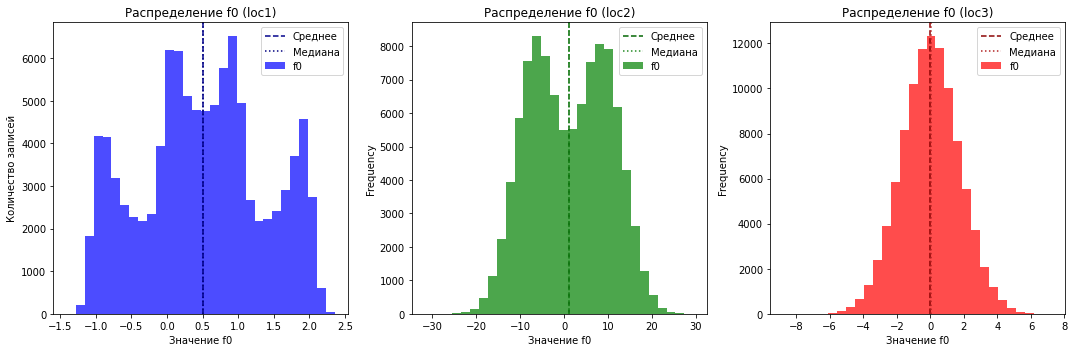

In [7]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

loc1['f0'].plot(kind='hist', bins=30, ax=ax1, color='blue', alpha=0.7)
ax1.set_title('Распределение f0 (loc1)')
ax1.set_xlabel('Значение f0')
ax1.set_ylabel('Количество записей')

loc2['f0'].plot(kind='hist', bins=30, ax=ax2, color='green', alpha=0.7)
ax2.set_title('Распределение f0 (loc2)')
ax2.set_xlabel('Значение f0')

loc3['f0'].plot(kind='hist', bins=30, ax=ax3, color='red', alpha=0.7)
ax3.set_title('Распределение f0 (loc3)')
ax3.set_xlabel('Значение f0')

# Добавляем средние и медианы
mean1, median1 = loc1['f0'].mean(), loc1['f0'].median()
ax1.axvline(mean1, color='darkblue', linestyle='--', label='Среднее')
ax1.axvline(median1, color='navy', linestyle=':', label='Медиана')
ax1.legend()

mean2, median2 = loc2['f0'].mean(), loc2['f0'].median()
ax2.axvline(mean2, color='darkgreen', linestyle='--', label='Среднее')
ax2.axvline(median2, color='forestgreen', linestyle=':', label='Медиана')
ax2.legend()

mean3, median3 = loc3['f0'].mean(), loc3['f0'].median()
ax3.axvline(mean3, color='darkred', linestyle='--', label='Среднее')
ax3.axvline(median3, color='firebrick', linestyle=':', label='Медиана')
ax3.legend()

# Показываем графики
plt.tight_layout()  # Чтобы графики не наезжали друг на друга
plt.show()

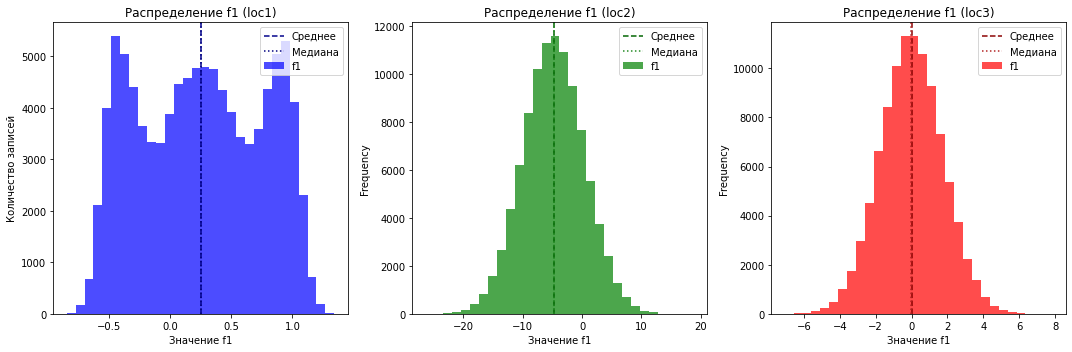

In [8]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

loc1['f1'].plot(kind='hist', bins=30, ax=ax1, color='blue', alpha=0.7)
ax1.set_title('Распределение f1 (loc1)')
ax1.set_xlabel('Значение f1')
ax1.set_ylabel('Количество записей')

loc2['f1'].plot(kind='hist', bins=30, ax=ax2, color='green', alpha=0.7)
ax2.set_title('Распределение f1 (loc2)')
ax2.set_xlabel('Значение f1')

loc3['f1'].plot(kind='hist', bins=30, ax=ax3, color='red', alpha=0.7)
ax3.set_title('Распределение f1 (loc3)')
ax3.set_xlabel('Значение f1')

# Добавляем средние и медианы
mean1, median1 = loc1['f1'].mean(), loc1['f1'].median()
ax1.axvline(mean1, color='darkblue', linestyle='--', label='Среднее')
ax1.axvline(median1, color='navy', linestyle=':', label='Медиана')
ax1.legend()

mean2, median2 = loc2['f1'].mean(), loc2['f1'].median()
ax2.axvline(mean2, color='darkgreen', linestyle='--', label='Среднее')
ax2.axvline(median2, color='forestgreen', linestyle=':', label='Медиана')
ax2.legend()

mean3, median3 = loc3['f1'].mean(), loc3['f1'].median()
ax3.axvline(mean3, color='darkred', linestyle='--', label='Среднее')
ax3.axvline(median3, color='firebrick', linestyle=':', label='Медиана')
ax3.legend()

# Показываем графики
plt.tight_layout()  # Чтобы графики не наезжали друг на друга
plt.show()

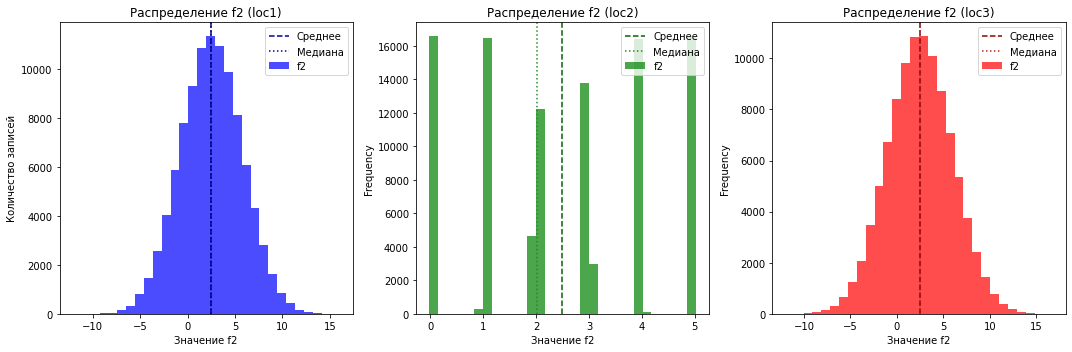

In [9]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

loc1['f2'].plot(kind='hist', bins=30, ax=ax1, color='blue', alpha=0.7)
ax1.set_title('Распределение f2 (loc1)')
ax1.set_xlabel('Значение f2')
ax1.set_ylabel('Количество записей')

loc2['f2'].plot(kind='hist', bins=30, ax=ax2, color='green', alpha=0.7)
ax2.set_title('Распределение f2 (loc2)')
ax2.set_xlabel('Значение f2')

loc3['f2'].plot(kind='hist', bins=30, ax=ax3, color='red', alpha=0.7)
ax3.set_title('Распределение f2 (loc3)')
ax3.set_xlabel('Значение f2')

# Добавляем средние и медианы
mean1, median1 = loc1['f2'].mean(), loc1['f2'].median()
ax1.axvline(mean1, color='darkblue', linestyle='--', label='Среднее')
ax1.axvline(median1, color='navy', linestyle=':', label='Медиана')
ax1.legend()

mean2, median2 = loc2['f2'].mean(), loc2['f2'].median()
ax2.axvline(mean2, color='darkgreen', linestyle='--', label='Среднее')
ax2.axvline(median2, color='forestgreen', linestyle=':', label='Медиана')
ax2.legend()

mean3, median3 = loc3['f2'].mean(), loc3['f2'].median()
ax3.axvline(mean3, color='darkred', linestyle='--', label='Среднее')
ax3.axvline(median3, color='firebrick', linestyle=':', label='Медиана')
ax3.legend()

# Показываем графики
plt.tight_layout()  # Чтобы графики не наезжали друг на друга
plt.show()

<div style="background-color: white; color: olive;">
    Распределения у нас очень разные: многомодальные (f0 и f1 в location1), бимодальное (f0 в location2), дискретное (f2 в location2). Кроме того, присутствует немало унимодальных распределений, близких к нормальным (f2 в location1; f1 в location2; f0, f1 и f2 в location3). Мне очень нравятся распределения признаков в третьей локации, они прямо как в учебнике.
</div>

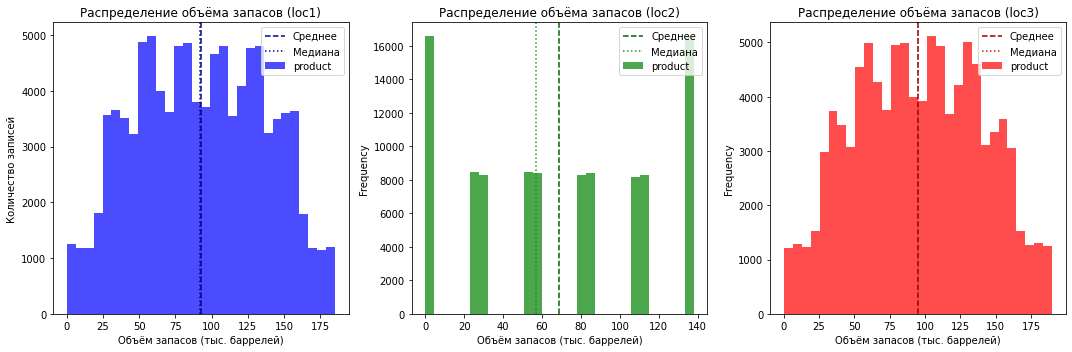

In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

loc1['product'].plot(kind='hist', bins=30, ax=ax1, color='blue', alpha=0.7)
ax1.set_title('Распределение объёма запасов (loc1)')
ax1.set_xlabel('Объём запасов (тыс. баррелей)')
ax1.set_ylabel('Количество записей')

loc2['product'].plot(kind='hist', bins=30, ax=ax2, color='green', alpha=0.7)
ax2.set_title('Распределение объёма запасов (loc2)')
ax2.set_xlabel('Объём запасов (тыс. баррелей)')

loc3['product'].plot(kind='hist', bins=30, ax=ax3, color='red', alpha=0.7)
ax3.set_title('Распределение объёма запасов (loc3)')
ax3.set_xlabel('Объём запасов (тыс. баррелей)')

mean1, median1 = loc1['product'].mean(), loc1['product'].median()
ax1.axvline(mean1, color='darkblue', linestyle='--', label='Среднее')
ax1.axvline(median1, color='navy', linestyle=':', label='Медиана')
ax1.legend()

mean2, median2 = loc2['product'].mean(), loc2['product'].median()
ax2.axvline(mean2, color='darkgreen', linestyle='--', label='Среднее')
ax2.axvline(median2, color='forestgreen', linestyle=':', label='Медиана')
ax2.legend()

mean3, median3 = loc3['product'].mean(), loc3['product'].median()
ax3.axvline(mean3, color='darkred', linestyle='--', label='Среднее')
ax3.axvline(median3, color='firebrick', linestyle=':', label='Медиана')
ax3.legend()

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Распределения запасов нефти по месторождениям первого и третьего регионом у нас многомодальные, но хотя бы имеющие отдалённо-колоколообразную форму, а вот у второго месторождения распределение дискретное.
</div>

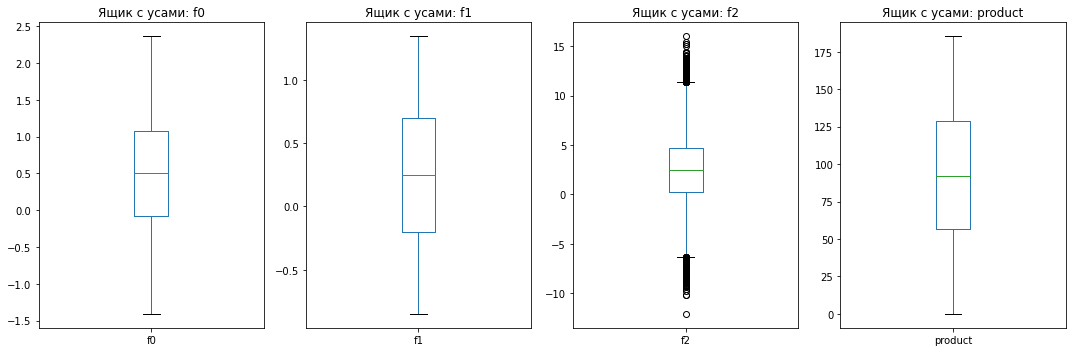

In [11]:
# Создаём фигуру с 4 графиками в одной строке
plt.figure(figsize=(15, 5))

# Список признаков для визуализации
features = ['f0', 'f1', 'f2', 'product']

# Строим ящики с усами для каждого признака
for i, feature in enumerate(features, 1):
    plt.subplot(1, 4, i)  # 1 строка, 4 столбца, i-й график
    loc1[feature].plot(kind='box', vert=True)
    plt.title(f'Ящик с усами: {feature}')

plt.tight_layout()  # Автоматическое выравнивание графиков
plt.show()

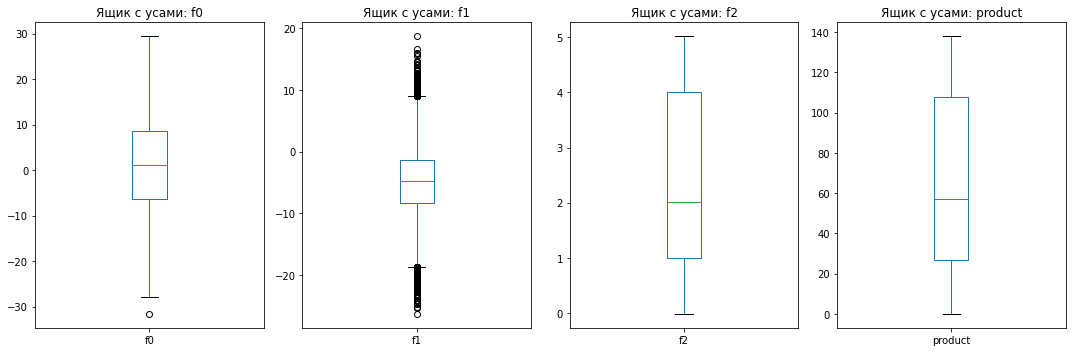

In [12]:
# Создаём фигуру с 4 графиками в одной строке
plt.figure(figsize=(15, 5))

# Список признаков для визуализации
features = ['f0', 'f1', 'f2', 'product']

# Строим ящики с усами для каждого признака
for i, feature in enumerate(features, 1):
    plt.subplot(1, 4, i)  # 1 строка, 4 столбца, i-й график
    loc2[feature].plot(kind='box', vert=True)
    plt.title(f'Ящик с усами: {feature}')

plt.tight_layout()  # Автоматическое выравнивание графиков
plt.show()

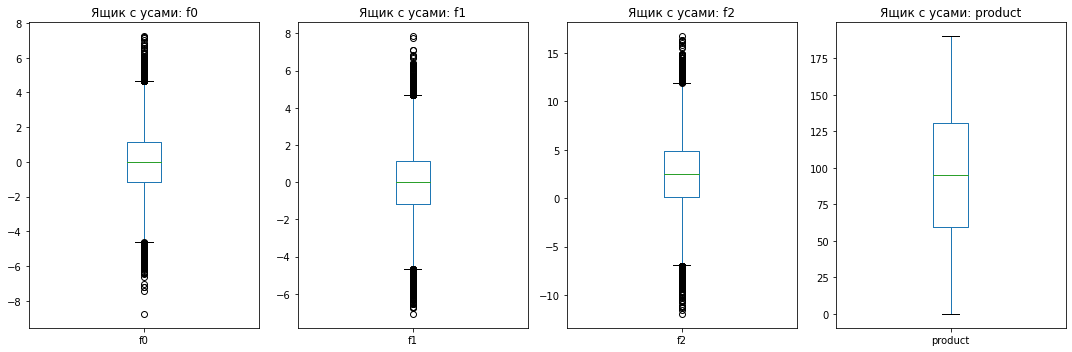

In [13]:
# Создаём фигуру с 4 графиками в одной строке
plt.figure(figsize=(15, 5))

# Список признаков для визуализации
features = ['f0', 'f1', 'f2', 'product']

# Строим ящики с усами для каждого признака
for i, feature in enumerate(features, 1):
    plt.subplot(1, 4, i)  # 1 строка, 4 столбца, i-й график
    loc3[feature].plot(kind='box', vert=True)
    plt.title(f'Ящик с усами: {feature}')

plt.tight_layout()  # Автоматическое выравнивание графиков
plt.show()

<div style="background-color: white; color: olive;">
    Просто что это такое? С таким распределением хорошей модели, боюсь, не получится. Возможно, стоит почистить данные? Но я нен вижу в условии проекта, чтобы мне это разрешалось(
</div>

<div style="background-color: white; color: olive;">
    Теперь немного подумаем о корреляции!
</div>

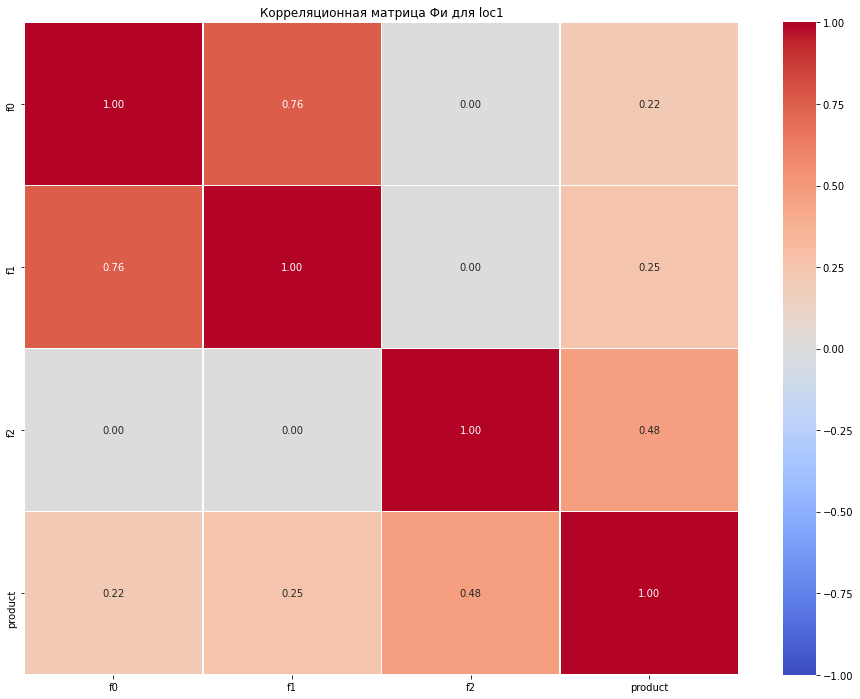

Пары признаков со значимой корреляцией (|r| > 0.6):
f1 и f0: 0.76


In [14]:
# Создаём копию датасета без столбца id
loc1_for_corr = loc1.drop(columns=['id'])

# Указываем столбцы, которые нужно рассматривать как интервальные (числовые)
interval_cols = ['f0', 'f1', 'f2', 'product']

# Вычисляем корреляционную матрицу Фи
phik_corr_matrix = loc1_for_corr.phik_matrix(interval_cols=interval_cols)

# Визуализация корреляционной матрицы
plt.figure(figsize=(16, 12))
sns.heatmap(
    phik_corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title('Корреляционная матрица Фи для loc1')
plt.show()

# Анализ мультиколлинеарности
high_corr_pairs = []
for i in range(len(phik_corr_matrix.columns)):
    for j in range(i):
        if abs(phik_corr_matrix.iloc[i, j]) > 0.6:
            pair = (
                phik_corr_matrix.columns[i],
                phik_corr_matrix.columns[j],
                phik_corr_matrix.iloc[i, j]
            )
            high_corr_pairs.append(pair)

print("Пары признаков со значимой корреляцией (|r| > 0.6):")
for pair in high_corr_pairs:
    print(f"{pair[0]} и {pair[1]}: {pair[2]:.2f}")

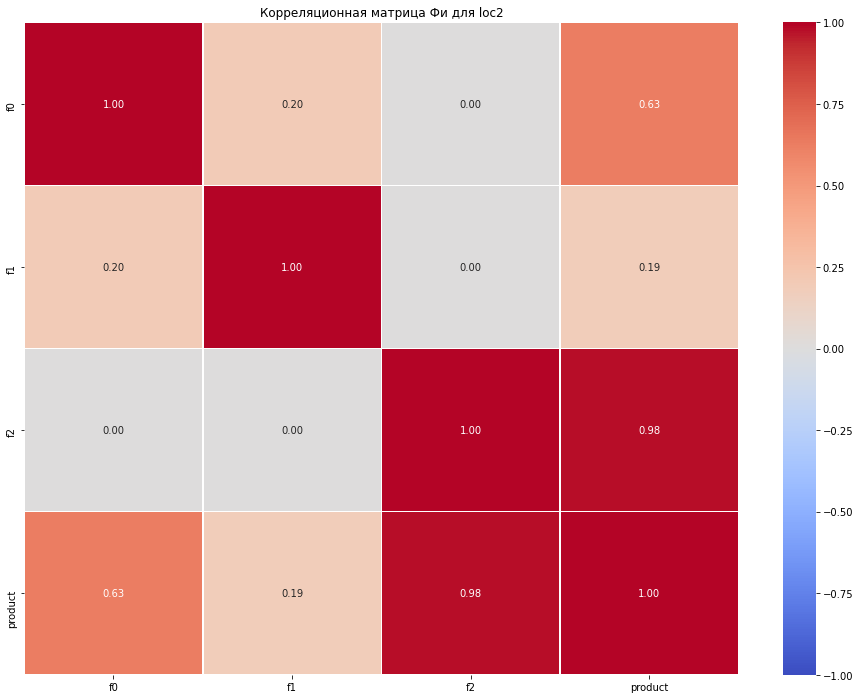

Пары признаков со значимой корреляцией (|r| > 0.6):
product и f0: 0.63
product и f2: 0.98


In [15]:
# Создаём копию датасета без столбца id
loc2_for_corr = loc2.drop(columns=['id'])

# Указываем столбцы, которые нужно рассматривать как интервальные (числовые)
interval_cols = ['f0', 'f1', 'f2', 'product']

# Вычисляем корреляционную матрицу Фи
phik_corr_matrix = loc2_for_corr.phik_matrix(interval_cols=interval_cols)

# Визуализация корреляционной матрицы
plt.figure(figsize=(16, 12))
sns.heatmap(
    phik_corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title('Корреляционная матрица Фи для loc2')
plt.show()

# Анализ мультиколлинеарности
high_corr_pairs = []
for i in range(len(phik_corr_matrix.columns)):
    for j in range(i):
        if abs(phik_corr_matrix.iloc[i, j]) > 0.6:
            pair = (
                phik_corr_matrix.columns[i],
                phik_corr_matrix.columns[j],
                phik_corr_matrix.iloc[i, j]
            )
            high_corr_pairs.append(pair)

print("Пары признаков со значимой корреляцией (|r| > 0.6):")
for pair in high_corr_pairs:
    print(f"{pair[0]} и {pair[1]}: {pair[2]:.2f}")

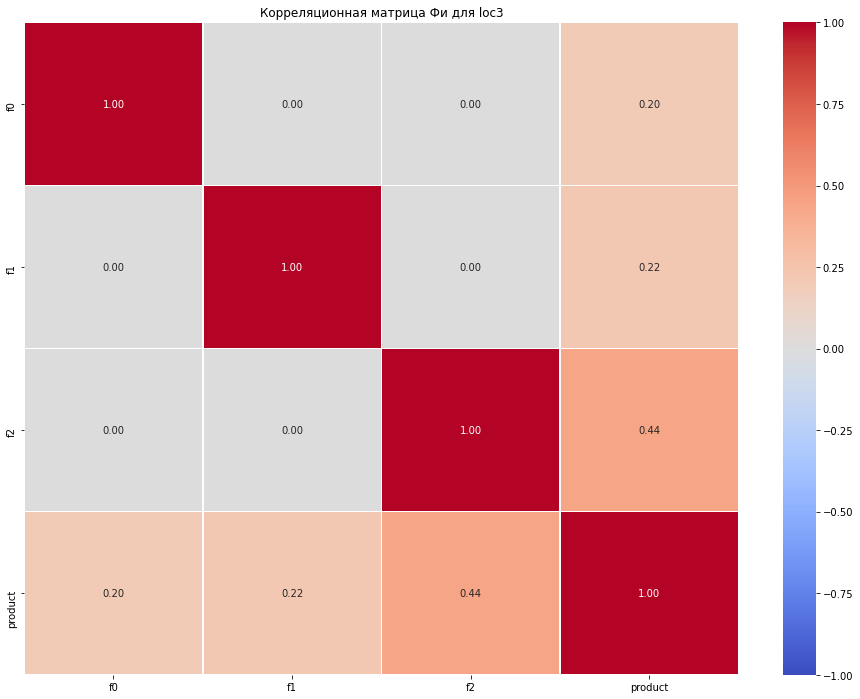

Пары признаков со значимой корреляцией (|r| > 0.6):


In [16]:
# Создаём копию датасета без столбца id
loc3_for_corr = loc3.drop(columns=['id'])

# Указываем столбцы, которые нужно рассматривать как интервальные (числовые)
interval_cols = ['f0', 'f1', 'f2', 'product']

# Вычисляем корреляционную матрицу Фи
phik_corr_matrix = loc3_for_corr.phik_matrix(interval_cols=interval_cols)

# Визуализация корреляционной матрицы
plt.figure(figsize=(16, 12))
sns.heatmap(
    phik_corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title('Корреляционная матрица Фи для loc3')
plt.show()

# Анализ мультиколлинеарности
high_corr_pairs = []
for i in range(len(phik_corr_matrix.columns)):
    for j in range(i):
        if abs(phik_corr_matrix.iloc[i, j]) > 0.6:
            pair = (
                phik_corr_matrix.columns[i],
                phik_corr_matrix.columns[j],
                phik_corr_matrix.iloc[i, j]
            )
            high_corr_pairs.append(pair)

print("Пары признаков со значимой корреляцией (|r| > 0.6):")
for pair in high_corr_pairs:
    print(f"{pair[0]} и {pair[1]}: {pair[2]:.2f}")

<div style="background-color: white; color: olive;">
    Имеется чрезвычайно сильная положительная линейная зависимость между признаком f2 и объёмами запасов в скважине для второго региона.
</div>

## Обучение и проверка модели

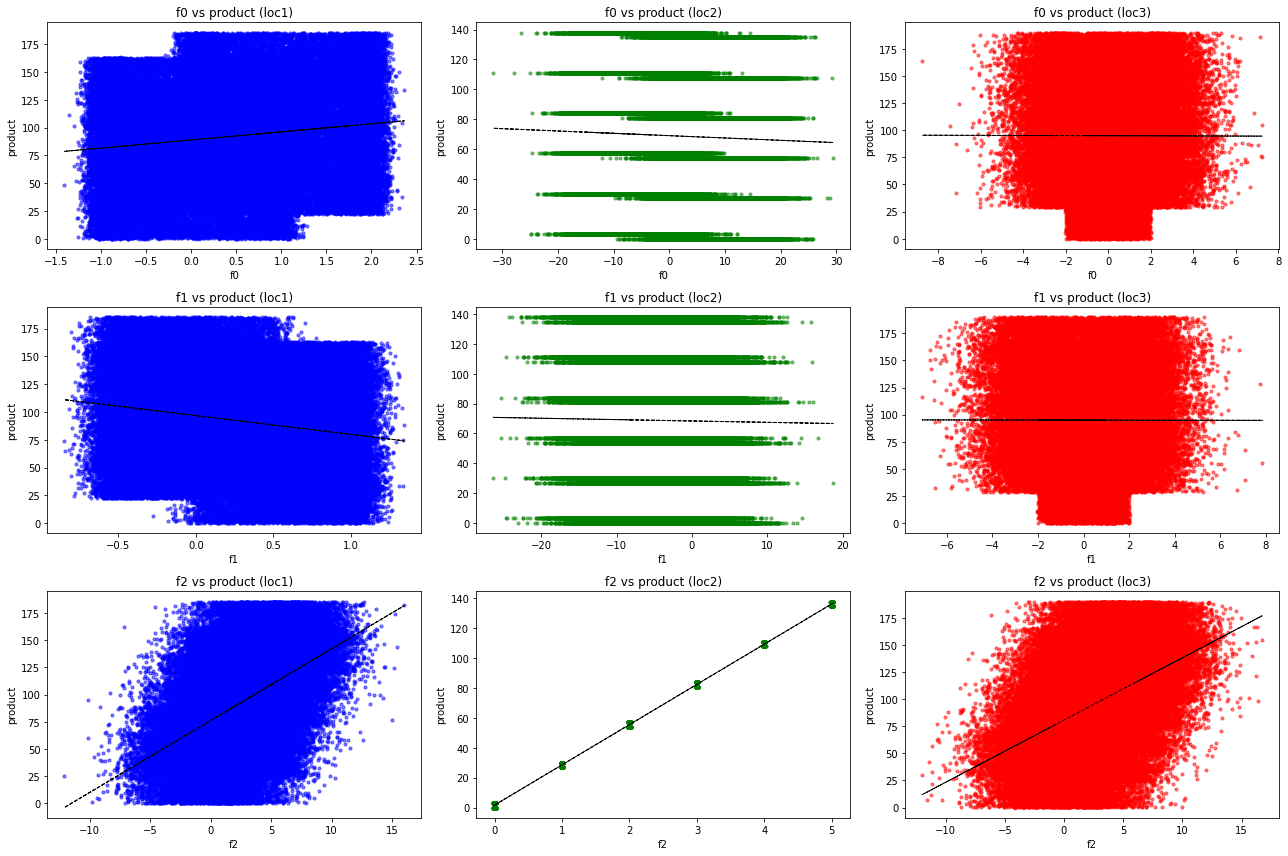

In [17]:
# Настройки для графиков
plt.figure(figsize=(18, 12))

# Список признаков для анализа
features_to_plot = ['f0', 'f1', 'f2']

# Цвета для каждого региона
colors = {'loc1': 'blue', 'loc2': 'green', 'loc3': 'red'}
region_names = ['loc1', 'loc2', 'loc3']
regions = [loc1, loc2, loc3]

# Строим scatterplot'ы для каждого признака и региона
for i, feature in enumerate(features_to_plot):
    for j, (region, name) in enumerate(zip(regions, region_names)):
        plt.subplot(3, 3, i * 3 + j + 1)  # 3 строки (по признакам), 3 столбца (по регионам)
        plt.scatter(
            region[feature],
            region['product'],
            color=colors[name],
            alpha=0.5,
            s=10
        )
        plt.xlabel(feature)
        plt.ylabel('product')
        plt.title(f'{feature} vs product ({name})')

        # Добавляем линию тренда для наглядности
        z = np.polyfit(region[feature], region['product'], 1)
        p = np.poly1d(z)
        plt.plot(region[feature], p(region[feature]), color='black', linestyle='--', linewidth=1)

plt.tight_layout()
plt.show()

<table>
    <tr>
        <th>Регион</th>
        <th>Признак</th>
        <th>Линейная зависимость</th>
        <th>Рекомендация</th>
    </tr>
    <tr>
        <td>loc1</td>
        <td>f0</td>
        <td>❌ Слабая</td>
        <td>Не информативен</td>
    </tr>
    <tr>
        <td>loc1</td>
        <td>f1</td>
        <td>❌ Слабая</td>
        <td>Не информативен</td>
    </tr>
    <tr>
        <td>loc1</td>
        <td>f2</td>
        <td>✅ Сильная</td>
        <td>Оставить как есть</td>
    </tr>
    <tr>
        <td>loc2</td>
        <td>f0</td>
        <td>❌ Отсутствует</td>
        <td>Не информативен</td>
    </tr>
    <tr>
        <td>loc2</td>
        <td>f1</td>
        <td>❌ Отсутствует</td>
        <td>Не информативен</td>
    </tr>
    <tr>
        <td>loc2</td>
        <td>f2</td>
        <td>✅ Идеальная</td>
        <td>Оставить как есть</td>
    </tr>
    <tr>
        <td>loc3</td>
        <td>f0</td>
        <td>❌ Нелинейная</td>
        <td>Логарифмировать product или f0</td>
    </tr>
    <tr>
        <td>loc3</td>
        <td>f1</td>
        <td>❌ Нелинейная</td>
        <td>Логарифмировать product или f1</td>
    </tr>
    <tr>
        <td>loc3</td>
        <td>f2</td>
        <td>✅ Умеренная</td>
        <td>Оставить как есть</td>
    </tr>
</table>

<div style="background-color: white; color: olive;">
    Итак! Мы можем улучшить качество модели для третьей локации, прологарифмировав признаки. Но тогда модель предсказаний для третьей локации не будет идентична моделям предсказаний для первых двух.
</div>

In [21]:
# --- Общие параметры ---
numerical_features = ['f0', 'f1', 'f2']
regions = [loc1, loc2, loc3]
region_names = ['loc1', 'loc2', 'loc3']
n_bootstrap = 1000
num_wells_to_develop = 200

# Функция для оценки качества
def assess_quality(row):
    if row['Относительная ошибка RMSE, %'] < 10:
        return "✅ Отлично"
    elif row['Относительная ошибка RMSE, %'] < 20:
        return "👍 Хорошо"
    elif row['Относительная ошибка RMSE, %'] < 30:
        return "🟡 Средне"
    else:
        return "❌ Плохо"

# Функция для логарифмирования
def log_transform(X):
    X = np.where(X <= 0, 1e-6, X)
    return np.log1p(X)

log_transformer = FunctionTransformer(log_transform)

# --- Определение пайплайнов для разных моделей ---
# 1. Базовая модель (без логарифмирования)
pipeline_lr = Pipeline(steps=[
    ('preprocessor', ColumnTransformer(transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_features)
    ])),
    ('regressor', LinearRegression())
])

# 2. Модель с полным логарифмированием
pipeline_lr_log = Pipeline(steps=[
    ('preprocessor', ColumnTransformer(transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('log', log_transformer),
            ('scaler', StandardScaler())
        ]), numerical_features)
    ])),
    ('regressor', LinearRegression())
])

# 3. Модель с частичным логарифмированием (только f0 и f1 для loc3)
pipeline_partial_log = Pipeline(steps=[
    ('preprocessor', ColumnTransformer(transformers=[
        ('f0_log', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('log', log_transformer)
        ]), ['f0']),
        ('f1_log', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('log', log_transformer)
        ]), ['f1']),
        ('f2_standard', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), ['f2'])
    ])),
    ('regressor', LinearRegression())
])

# Список пайплайнов для каждого региона и типа модели
model_configs = [
    {
        'name': 'Без логарифмирования',
        'pipelines': [pipeline_lr, pipeline_lr, pipeline_lr],
        'results': {}
    },
    {
        'name': 'Полное логарифмирование',
        'pipelines': [pipeline_lr_log, pipeline_lr_log, pipeline_lr_log],
        'results': {}
    },
    {
        'name': 'Частичное логарифмирование',
        'pipelines': [pipeline_lr, pipeline_lr, pipeline_partial_log],
        'results': {}
    }
]

# --- Общая функция для обучения и оценки модели ---
def evaluate_model(regions, region_names, pipelines, model_name):
    results = {}
    cross_val_results = {}

    for region, name, pipeline in zip(regions, region_names, pipelines):
        X = region.drop(columns=['id', 'product'])
        y = region['product']

        # Разбиваем данные
        X_train, X_valid, y_train, y_valid = train_test_split(
            X, y, test_size=0.25, random_state=42
        )

        # Обучаем модель
        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_valid)

        # Вычисляем метрики
        rmse = np.sqrt(mean_squared_error(y_valid, predictions))
        mae = mean_absolute_error(y_valid, predictions)
        r2 = r2_score(y_valid, predictions)

        # Базовая модель (предсказание среднего)
        baseline_pred = np.full_like(y_valid, y_train.mean())
        baseline_rmse = np.sqrt(mean_squared_error(y_valid, baseline_pred))

        # Относительная ошибка
        relative_rmse = rmse / y_valid.mean()

        # Сохраняем результаты
        results[name] = {
            'rmse': rmse,
            'mae': mae,
            'r2': r2,
            'baseline_rmse': baseline_rmse,
            'relative_rmse': relative_rmse,
            'mean_product': y_valid.mean(),
            'target': y_valid.values,
            'predictions': predictions
        }

        # Кросс-валидация
        kf = KFold(n_splits=4, shuffle=True, random_state=42)
        rmse_scores = []
        for train_index, valid_index in kf.split(X):
            X_train_cv, X_valid_cv = X.iloc[train_index], X.iloc[valid_index]
            y_train_cv, y_valid_cv = y.iloc[train_index], y.iloc[valid_index]
            pipeline.fit(X_train_cv, y_train_cv)
            predictions_cv = pipeline.predict(X_valid_cv)
            rmse_cv = np.sqrt(mean_squared_error(y_valid_cv, predictions_cv))
            rmse_scores.append(rmse_cv)

        mean_rmse = np.mean(rmse_scores)
        std_rmse = np.std(rmse_scores)
        cross_val_results[name] = {'mean_rmse': mean_rmse, 'std_rmse': std_rmse, 'scores': rmse_scores}

    # Формируем таблицу результатов
    results_df = pd.DataFrame.from_dict(results, orient='index')
    results_df['RMSE'] = results_df['rmse']
    results_df['MAE'] = results_df['mae']
    results_df['R²'] = results_df['r2']
    results_df['Baseline RMSE'] = results_df['baseline_rmse']
    results_df['Относительная ошибка RMSE, %'] = (results_df['relative_rmse'] * 100).round(2)
    results_df['Средний product'] = results_df['mean_product']
    results_df = results_df.drop(columns=['rmse', 'mae', 'r2', 'baseline_rmse', 'relative_rmse', 'mean_product'])
    results_df['Оценка качества'] = results_df.apply(assess_quality, axis=1)

    # Выводим таблицу
    results_df = results_df[['RMSE', 'MAE', 'R²', 'Baseline RMSE', 'Относительная ошибка RMSE, %', 'Средний product', 'Оценка качества']]

    # Печатаем результаты кросс-валидации
    print(f"\n🔍 Результаты кросс-валидации (K=4) для модели с {model_name}:\n")
    for name in region_names:
        print(f"Регион {name}: Средний RMSE (K=4): {cross_val_results[name]['mean_rmse']:.2f} ± {cross_val_results[name]['std_rmse']:.2f}, "
              f"Текущий RMSE: {results[name]['rmse']:.2f}")

    return results, results_df, cross_val_results

# --- Запуск оценки для всех моделей ---
all_results = {}
all_dfs = {}
all_cross_val = {}

for config in model_configs:
    model_name = config['name']
    pipelines = config['pipelines']
    results, results_df, cross_val_results = evaluate_model(regions, region_names, pipelines, model_name)
    all_results[model_name] = results
    all_dfs[model_name] = results_df
    all_cross_val[model_name] = cross_val_results

# Выводим таблицы для каждой модели
for model_name in all_results:
    print(f"\n📊 Результаты для модели с {model_name}:")
    display(all_dfs[model_name])

# --- Сравнение всех моделей ---
print("\n📊 Сравнение всех моделей:\n")
comparison_df = pd.DataFrame({
    'Регион': region_names,
    'RMSE (без логарифмирования)': [all_results['Без логарифмирования'][name]['rmse'] for name in region_names],
    'RMSE (полное логарифмирование)': [all_results['Полное логарифмирование'][name]['rmse'] for name in region_names],
    'RMSE (частичное логарифмирование)': [all_results['Частичное логарифмирование'][name]['rmse'] for name in region_names],
    'Улучшение (полное)': [
        all_results['Без логарифмирования'][name]['rmse'] - all_results['Полное логарифмирование'][name]['rmse']
        for name in region_names
    ],
    'Улучшение (частичное)': [
        all_results['Без логарифмирования'][name]['rmse'] - all_results['Частичное логарифмирование'][name]['rmse']
        for name in region_names
    ]
})

comparison_df['Улучшение (полное), %'] = (
    (comparison_df['Улучшение (полное)'] / comparison_df['RMSE (без логарифмирования)']) * 100
).round(2)
comparison_df['Улучшение (частичное), %'] = (
    (comparison_df['Улучшение (частичное)'] / comparison_df['RMSE (без логарифмирования)']) * 100
).round(2)

display(comparison_df)


🔍 Результаты кросс-валидации (K=4) для модели с Без логарифмирования:

Регион loc1: Средний RMSE (K=4): 37.69 ± 0.18, Текущий RMSE: 37.76
Регион loc2: Средний RMSE (K=4): 0.89 ± 0.00, Текущий RMSE: 0.89
Регион loc3: Средний RMSE (K=4): 40.06 ± 0.05, Текущий RMSE: 40.15

🔍 Результаты кросс-валидации (K=4) для модели с Полное логарифмирование:

Регион loc1: Средний RMSE (K=4): 38.03 ± 0.17, Текущий RMSE: 38.10
Регион loc2: Средний RMSE (K=4): 11.62 ± 0.01, Текущий RMSE: 11.63
Регион loc3: Средний RMSE (K=4): 40.02 ± 0.06, Текущий RMSE: 40.11

🔍 Результаты кросс-валидации (K=4) для модели с Частичное логарифмирование:

Регион loc1: Средний RMSE (K=4): 37.69 ± 0.18, Текущий RMSE: 37.76
Регион loc2: Средний RMSE (K=4): 0.89 ± 0.00, Текущий RMSE: 0.89
Регион loc3: Средний RMSE (K=4): 39.78 ± 0.05, Текущий RMSE: 39.87

📊 Результаты для модели с Без логарифмирования:


,RMSE,MAE,R²,Baseline RMSE,"Относительная ошибка RMSE, %",Средний product,Оценка качества
loc1,37.756600,31.047682,0.272829,44.277235,40.89,92.325956,❌ Плохо
loc2,0.890280,0.717012,0.999625,45.944859,1.30,68.725381,✅ Отлично
loc3,40.145872,32.896959,0.196347,44.782777,42.19,95.150999,❌ Плохо



📊 Результаты для модели с Полное логарифмирование:


,RMSE,MAE,R²,Baseline RMSE,"Относительная ошибка RMSE, %",Средний product,Оценка качества
loc1,38.098691,31.347795,0.259592,44.277235,41.27,92.325956,❌ Плохо
loc2,11.626900,10.726395,0.935959,45.944859,16.92,68.725381,👍 Хорошо
loc3,40.110476,32.881088,0.197764,44.782777,42.15,95.150999,❌ Плохо



📊 Результаты для модели с Частичное логарифмирование:


,RMSE,MAE,R²,Baseline RMSE,"Относительная ошибка RMSE, %",Средний product,Оценка качества
loc1,37.756600,31.047682,0.272829,44.277235,40.89,92.325956,❌ Плохо
loc2,0.890280,0.717012,0.999625,45.944859,1.30,68.725381,✅ Отлично
loc3,39.865279,32.724378,0.207542,44.782777,41.90,95.150999,❌ Плохо



📊 Сравнение всех моделей:



,Регион,RMSE (без логарифмирования),RMSE (полное логарифмирование),RMSE (частичное логарифмирование),Улучшение (полное),Улучшение (частичное),"Улучшение (полное), %","Улучшение (частичное), %"
0,loc1,37.756600,38.098691,37.756600,-0.342091,0.000000,-0.91,0.0
1,loc2,0.890280,11.626900,0.890280,-10.736620,0.000000,-1205.98,0.0
2,loc3,40.145872,40.110476,39.865279,0.035396,0.280593,0.09,0.7


<div style="background-color: white; color: olive;">
    Итак, мы создали модели машинного обучения, и они так себе работают. Я вернусь на пару шагов назад и попробую:
    <br/>
    1) Взглянуть на выбросы;
    <br/>
    2) Логарифмировать признаки скважин.
    <br/>
    <br/>
    Тем не менее, удалось сохранить как реальные показатели продукта, так и предсказанные в соответствующий словарь!
</div>

/opt/conda/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 10060 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/opt/conda/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 9989 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/opt/conda/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:201: RuntimeWarning: Glyph 10060 missing from current font.
  font.set_text(s, 0, flags=flags)
/opt/conda/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:201: RuntimeWarning: Glyph 9989 missing from current font.
  font.set_text(s, 0, flags=flags)


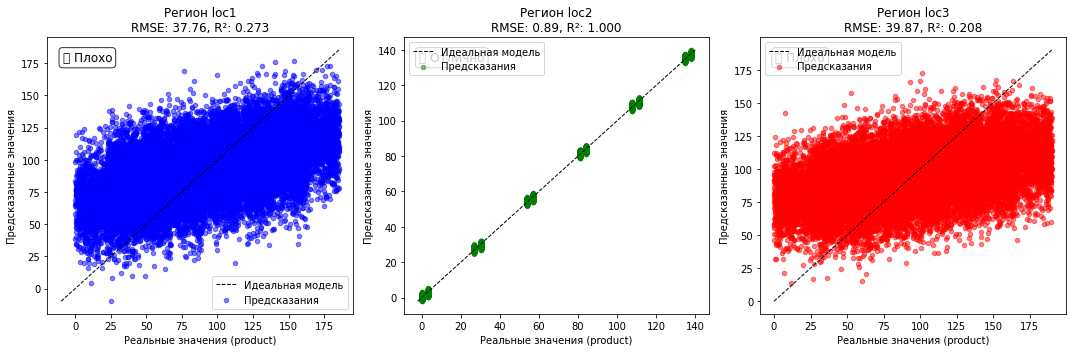

In [22]:
# Настройки для графиков
plt.figure(figsize=(15, 5))

# Цвета для каждого региона
colors = {'loc1': 'blue', 'loc2': 'green', 'loc3': 'red'}

# Строим графики для каждого региона
for i, (name, data) in enumerate(results.items(), 1):
    plt.subplot(1, 3, i)

    # Реальные и предсказанные значения
    y_true = data['target']  # Исправлено: используем ключ 'target'
    y_pred = data['predictions']

    # Строим scatter plot
    plt.scatter(y_true, y_pred, color=colors[name], alpha=0.5, s=20, label='Предсказания')

    # Добавляем линию y = x (идеальное предсказание)
    max_val = max(max(y_true), max(y_pred))
    min_val = min(min(y_true), min(y_pred))
    plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', linewidth=1, label='Идеальная модель')

    # Подписи и легенда
    plt.xlabel('Реальные значения (product)')
    plt.ylabel('Предсказанные значения')
    plt.title(f'Регион {name}\nRMSE: {data["rmse"]:.2f}, R²: {r2_score(y_true, y_pred):.3f}')
    plt.legend()

    # Добавляем аннотацию с оценкой качества
    # Получаем оценку качества из results_df
    quality = results_df.loc[name, 'Оценка качества']
    plt.text(
        0.05, 0.95,
        f'{quality}',
        transform=plt.gca().transAxes,
        fontsize=12,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
    )

plt.tight_layout()
plt.show()

<div style="background-color: white; color: olive;">
    Модели работают так себе из-за не самых репрезентативных распределений признаков. Точно ли стоит использовать именно модель линейной регрессии в таком случае?
    <br/>
    Есть ещё идея: объединить вместе все три датасета, после обучить модель на максимальном количестве данных, и её применить к каждому датасету по отдельности.
</div>

## Подготовка к расчёту прибыли

<div style="background-color: white; color: olive;">
    В условиях задачи сказано:
    <br/>
    При разведке региона исследуют 500 точек, из которых с помощью машинного обучения выбирают 200 лучших для разработки.
    <br/>
    Бюджет на разработку скважин в регионе — 10 млрд рублей.
    <br/>
    При нынешних ценах один баррель сырья приносит 450 рублей дохода. Доход с каждой единицы продукта составляет 450 тыс. рублей, поскольку объём указан в тысячах баррелей.
    <br/>
    После оценки рисков нужно оставить лишь те регионы, в которых вероятность убытков меньше 2.5%. Среди них выбирают регион с наибольшей средней прибылью.
    <br/>
    <br/>
    Другими словами, разработать в регионе 200 скважин стоит 10 млрд. рублей. Так как в условии задачи ничего не говорится о налогах, обеспечении персонала, транспортных расходах и т.д., то либо это всё уже включено (примерно) в данные 10 миллиардов, либо мы имеем дело с валовой прибылью которая эквивалентна 450 т.р. умножить на product двухсот лучших скважин региона минус 10 млрд.р.
    <br/>
    <br/>
    Ну, давайте познакомимся с основными константами и переменными, необходимыми для расчёта.
</div>

<div style="background-color: white; color: olive;">
    total_budget - это те самые 10 миллиардов рублей;
    <br/>
    num_wells_to_develop - это те 200 скважин, на которые мы сливаем 10 миллиардов рублей;
    <br/>
    revenue_per_product - это стомость 1000 баррелей нефти, что равно стоимости единицы "product" в наших данных.
</div>

In [23]:
TOTAL_BUDGET = 10_000_000_000
NUM_WELLS_TO_DEVELOP = 200
REVENUE_PER_PRODUCT = 450_000

<div style="background-color: white; color: olive;">
    Перейдём к тем данным, что мы можем вытянуть из исходных:
    <br/>
    cost_per_well - это стоимость разработки одной скважины;
    <br/>
    min_profit_volume - минимальный объём сырья в скважине для её безубыточности.
</div>

In [24]:
cost_per_well = TOTAL_BUDGET / NUM_WELLS_TO_DEVELOP
min_profit_volume = cost_per_well / REVENUE_PER_PRODUCT  # Минимальный объём сырья (в единицах product)

print(f"Стоимость разработки одной скважины: {cost_per_well / 1_000_000_000:.2f} млрд рублей")
print(f"Минимальный объём сырья для безубыточности одной скважины: {min_profit_volume:.2f} тыс. баррелей\n")

Стоимость разработки одной скважины: 0.05 млрд рублей
Минимальный объём сырья для безубыточности одной скважины: 111.11 тыс. баррелей



<div style="background-color: white; color: olive;">
    Теперь сравним те запасы ресурсов, что нужны для безубыточной разработки скважины, со средними запасами по каждому региону!
</div>

In [25]:
print("📊 Сравнение среднего запаса с минимальным объёмом для безубыточности:\n")
profitability_df = pd.DataFrame({
    'Регион': region_names,
    'Средний запас (тыс. баррелей)': [results[name]['mean_product'] for name in region_names],
    'Минимальный объём (тыс. баррелей)': min_profit_volume,
    'Прибыльный?': [
        '✅ Да' if results[name]['mean_product'] > min_profit_volume else '❌ Нет'
        for name in region_names
    ]
})

display(profitability_df)

📊 Сравнение среднего запаса с минимальным объёмом для безубыточности:



,Регион,Средний запас (тыс. баррелей),Минимальный объём (тыс. баррелей),Прибыльный?
0,loc1,92.325956,111.111111,❌ Нет
1,loc2,68.725381,111.111111,❌ Нет
2,loc3,95.150999,111.111111,❌ Нет


<div style="background-color: white; color: olive;">
    Итак: для безубыточности необходимо, чтобы скважина имела запас не менее 111 тысяч баррелей, средние показатели каждого из имеющихся регионов куда слабее, лучшие -- у третьего региона. Возможно, там имеет наибольший резон разведывать 500 скважин, т.к. 200 из них с большей вероятностью окажутся выгодными.
</div>

## Расчёт прибыли и рисков 

In [26]:
def calculate_profit(predictions, target):
    top_wells_indices = np.argsort(predictions)[-NUM_WELLS_TO_DEVELOP:]
    total_product = np.sum(target[top_wells_indices])
    profit = (total_product * REVENUE_PER_PRODUCT) - TOTAL_BUDGET
    return profit

<div style="background-color: white; color: olive;">
    У нас появилась функция, которая:
    <br/>
    1) Находит из выбранного набора скважин (в нашем случае исследуется 500 скважин, но, если вдруг бюджет будет позволять исследоавать 600, эта функция останется актуальной) 200 с наилучшими предсказаниями продакшена;
    <br/>
    2) Суммирует фактические показатели продакшена данных скважин;
    <br/>
    3) Рассчитывает, сколько денег можно выручить, продав запасы данных скважин, и вычитает из этой цифры бюджет на разработку 200 скважин, рассчитывая прибыль.
</div>

<div style="background-color: white; color: olive;">
    Теперь как расчитать прибыль и риски? Нам нужно, чтобы 200 лучших точек из 500 случайных давали более 10 миллиардов рублей прибыли (если получать прибыль перемножением объёма на стоимость данного объёма).
</div>

📊 Распределение прибыли для региона loc1 (Bootstrap, 1000 выборок по 500 точек, топ-200):
  Средняя прибыль: 0.40 млрд рублей
  95% доверительный интервал: [-0.11, 0.90] млрд рублей
  Риск убытков: 6.00%
  Минимальный объём сырья для безубыточности: 111.11 тыс. баррелей


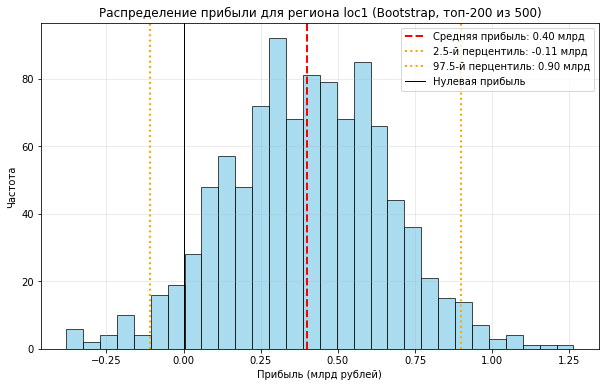

In [27]:
# --- Bootstrap-анализ для loc1 (500 точек, топ-200) ---
np.random.seed(42)

predictions_loc1 = results['loc1']['predictions']
target_loc1 = results['loc1']['target']

n_bootstrap = 1000
bootstrap_profits_loc1 = []

for _ in range(n_bootstrap):
    sample_indices = np.random.choice(len(predictions_loc1), size=500, replace=True)
    sample_predictions = predictions_loc1[sample_indices]
    sample_target = target_loc1[sample_indices]
    profit = calculate_profit(sample_predictions, sample_target)
    bootstrap_profits_loc1.append(profit)

bootstrap_profits_loc1 = np.array(bootstrap_profits_loc1)

mean_profit_loc1 = np.mean(bootstrap_profits_loc1)
ci_lower_loc1 = np.percentile(bootstrap_profits_loc1, 2.5)  # 95% доверительный интервал
ci_upper_loc1 = np.percentile(bootstrap_profits_loc1, 97.5)
risk_loc1 = np.sum(bootstrap_profits_loc1 < 0) / n_bootstrap * 100  # Риск убытков

print("📊 Распределение прибыли для региона loc1 (Bootstrap, 1000 выборок по 500 точек, топ-200):")
print(f"  Средняя прибыль: {mean_profit_loc1 / 1_000_000_000:.2f} млрд рублей")
print(f"  95% доверительный интервал: [{ci_lower_loc1 / 1_000_000_000:.2f}, {ci_upper_loc1 / 1_000_000_000:.2f}] млрд рублей")
print(f"  Риск убытков: {risk_loc1:.2f}%")
print(f"  Минимальный объём сырья для безубыточности: {min_profit_volume:.2f} тыс. баррелей")


# Визуализация
plt.figure(figsize=(10, 6))
plt.hist(bootstrap_profits_loc1 / 1_000_000_000, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(mean_profit_loc1 / 1_000_000_000, color='red', linestyle='--', linewidth=2, label=f'Средняя прибыль: {mean_profit_loc1 / 1_000_000_000:.2f} млрд')
plt.axvline(ci_lower_loc1 / 1_000_000_000, color='orange', linestyle=':', linewidth=2, label=f'2.5-й перцентиль: {ci_lower_loc1 / 1_000_000_000:.2f} млрд')
plt.axvline(ci_upper_loc1 / 1_000_000_000, color='orange', linestyle=':', linewidth=2, label=f'97.5-й перцентиль: {ci_upper_loc1 / 1_000_000_000:.2f} млрд')
plt.axvline(0, color='black', linestyle='-', linewidth=1, label='Нулевая прибыль')
plt.xlabel('Прибыль (млрд рублей)')
plt.ylabel('Частота')
plt.title('Распределение прибыли для региона loc1 (Bootstrap, топ-200 из 500)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


📊 Распределение прибыли для региона loc2 (Bootstrap, 1000 выборок по 500 точек, топ-200):
  Средняя прибыль: 0.45 млрд рублей
  95% доверительный интервал: [0.05, 0.83] млрд рублей
  Риск убытков: 0.90%
  Минимальный объём сырья для безубыточности: 111.11 тыс. баррелей


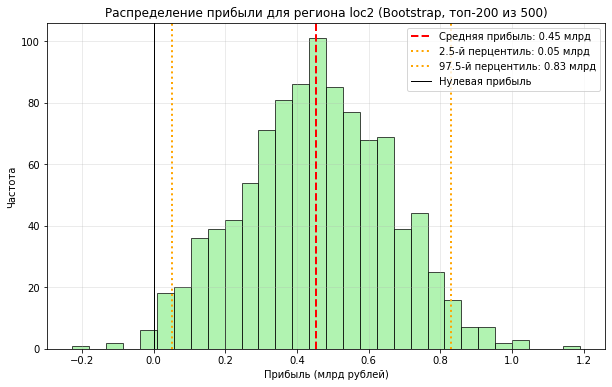

In [29]:
# --- Bootstrap-анализ для loc2 (500 точек, топ-200) ---
predictions_loc2 = results['loc2']['predictions']
target_loc2 = results['loc2']['target']

bootstrap_profits_loc2 = []
for _ in range(n_bootstrap):
    sample_indices = np.random.choice(len(predictions_loc2), size=500, replace=True)
    sample_predictions = predictions_loc2[sample_indices]
    sample_target = target_loc2[sample_indices]
    profit = calculate_profit(sample_predictions, sample_target)
    bootstrap_profits_loc2.append(profit)

bootstrap_profits_loc2 = np.array(bootstrap_profits_loc2)

mean_profit_loc2 = np.mean(bootstrap_profits_loc2)
ci_lower_loc2 = np.percentile(bootstrap_profits_loc2, 2.5)  # 95% доверительный интервал
ci_upper_loc2 = np.percentile(bootstrap_profits_loc2, 97.5)
risk_loc2 = np.sum(bootstrap_profits_loc2 < 0) / n_bootstrap * 100  # Риск убытков

print("\n📊 Распределение прибыли для региона loc2 (Bootstrap, 1000 выборок по 500 точек, топ-200):")
print(f"  Средняя прибыль: {mean_profit_loc2 / 1_000_000_000:.2f} млрд рублей")
print(f"  95% доверительный интервал: [{ci_lower_loc2 / 1_000_000_000:.2f}, {ci_upper_loc2 / 1_000_000_000:.2f}] млрд рублей")
print(f"  Риск убытков: {risk_loc2:.2f}%")
print(f"  Минимальный объём сырья для безубыточности: {min_profit_volume:.2f} тыс. баррелей")


# Визуализация
plt.figure(figsize=(10, 6))
plt.hist(bootstrap_profits_loc2 / 1_000_000_000, bins=30, color='lightgreen', edgecolor='black', alpha=0.7)
plt.axvline(mean_profit_loc2 / 1_000_000_000, color='red', linestyle='--', linewidth=2, label=f'Средняя прибыль: {mean_profit_loc2 / 1_000_000_000:.2f} млрд')
plt.axvline(ci_lower_loc2 / 1_000_000_000, color='orange', linestyle=':', linewidth=2, label=f'2.5-й перцентиль: {ci_lower_loc2 / 1_000_000_000:.2f} млрд')
plt.axvline(ci_upper_loc2 / 1_000_000_000, color='orange', linestyle=':', linewidth=2, label=f'97.5-й перцентиль: {ci_upper_loc2 / 1_000_000_000:.2f} млрд')
plt.axvline(0, color='black', linestyle='-', linewidth=1, label='Нулевая прибыль')
plt.xlabel('Прибыль (млрд рублей)')
plt.ylabel('Частота')
plt.title('Распределение прибыли для региона loc2 (Bootstrap, топ-200 из 500)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


📊 Распределение прибыли для региона loc3 (Bootstrap, 1000 выборок по 500 точек, топ-200):
  Средняя прибыль: 0.43 млрд рублей
  95% доверительный интервал: [-0.07, 0.96] млрд рублей
  Риск убытков: 5.50%
  Минимальный объём сырья для безубыточности: 111.11 тыс. баррелей


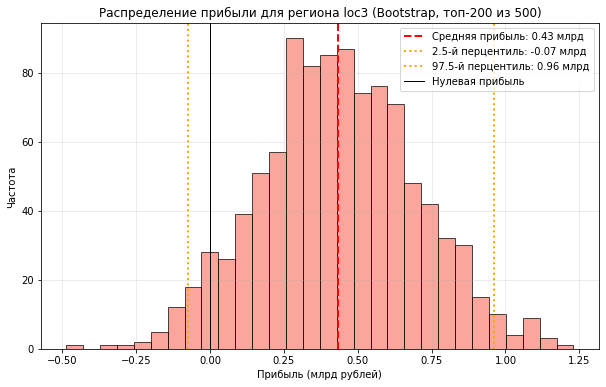

In [31]:
# --- Bootstrap-анализ для loc3 (500 точек, топ-200) ---
predictions_loc3 = results['loc3']['predictions']
target_loc3 = results['loc3']['target']

bootstrap_profits_loc3 = []
for _ in range(n_bootstrap):
    sample_indices = np.random.choice(len(predictions_loc3), size=500, replace=True)
    sample_predictions = predictions_loc3[sample_indices]
    sample_target = target_loc3[sample_indices]
    profit = calculate_profit(sample_predictions, sample_target)
    bootstrap_profits_loc3.append(profit)

bootstrap_profits_loc3 = np.array(bootstrap_profits_loc3)

mean_profit_loc3 = np.mean(bootstrap_profits_loc3)
ci_lower_loc3 = np.percentile(bootstrap_profits_loc3, 2.5)  # 95% доверительный интервал
ci_upper_loc3 = np.percentile(bootstrap_profits_loc3, 97.5)
risk_loc3 = np.sum(bootstrap_profits_loc3 < 0) / n_bootstrap * 100  # Риск убытков

print("\n📊 Распределение прибыли для региона loc3 (Bootstrap, 1000 выборок по 500 точек, топ-200):")
print(f"  Средняя прибыль: {mean_profit_loc3 / 1_000_000_000:.2f} млрд рублей")
print(f"  95% доверительный интервал: [{ci_lower_loc3 / 1_000_000_000:.2f}, {ci_upper_loc3 / 1_000_000_000:.2f}] млрд рублей")
print(f"  Риск убытков: {risk_loc3:.2f}%")
print(f"  Минимальный объём сырья для безубыточности: {min_profit_volume:.2f} тыс. баррелей")


# Визуализация
plt.figure(figsize=(10, 6))
plt.hist(bootstrap_profits_loc3 / 1_000_000_000, bins=30, color='salmon', edgecolor='black', alpha=0.7)
plt.axvline(mean_profit_loc3 / 1_000_000_000, color='red', linestyle='--', linewidth=2, label=f'Средняя прибыль: {mean_profit_loc3 / 1_000_000_000:.2f} млрд')
plt.axvline(ci_lower_loc3 / 1_000_000_000, color='orange', linestyle=':', linewidth=2, label=f'2.5-й перцентиль: {ci_lower_loc3 / 1_000_000_000:.2f} млрд')
plt.axvline(ci_upper_loc3 / 1_000_000_000, color='orange', linestyle=':', linewidth=2, label=f'97.5-й перцентиль: {ci_upper_loc3 / 1_000_000_000:.2f} млрд')
plt.axvline(0, color='black', linestyle='-', linewidth=1, label='Нулевая прибыль')
plt.xlabel('Прибыль (млрд рублей)')
plt.ylabel('Частота')
plt.title('Распределение прибыли для региона loc3 (Bootstrap, топ-200 из 500)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<div style="background-color: white; color: olive;">
    Итак, что мы сделали?
    <br/>
    1) Сгенерировали 1000 случайных выборок по 500 скважин для каждого набора данных;
    <br/>
    2) Для каждой выборки расчитали стоимость общих запасов 200 самых богатых скважин;
    <br/>
    3) Проанализировали распределение прибыли и шанс убытков (т.е. долю выборок, где топ-200 скважин не окупаются);
    <br/>
    4) Визуализировали всё это.
</div>

<div style="background-color: #424242; color: #ffd600;">
    Так как нужно оставить лишь те регионы, в которых вероятность убытков меньше 2.5%, то нам подходит лишь регион №2. В регионе №1 риск убытков составляет 6%, а в регионе №3 — 5.5%. Так что второй регион с риском убытков менее 1% нам подходит в самый раз!
</div>

Поставьте 'x' в выполненных пунктах. Далее нажмите Shift+Enter.